# Week 6 — A Seq2Seq Paraphraser with Attention (built from scratch)

**Goal (syllabus unit IV, sequence-to-sequence models and attention):** build an **encoder–decoder** network that rewrites a sentence in different words. In `13_attack` it becomes a weapon: paraphrase AI essays and see whether the detector from `08` can still catch them, which is the logic behind the demo's "try to fool it" button.

Architecture, in viva order:
- **Encoder:** a bidirectional GRU reads the source sentence and produces one vector per token.
- **Decoder:** a GRU writes the paraphrase one token at a time, each step conditioned on what it has written so far.
- **Attention (Bahdanau / additive):** at every decoding step, the decoder scores *every* encoder vector for relevance, turns the scores into weights (softmax), and reads a weighted average (the *context vector*). Without attention the whole source must squeeze through one fixed-size vector; with it, the decoder can "look back" at the relevant source words. That's the idea that later grew into transformers.

**Honest expectation:** this is a ~20M-parameter model trained from scratch on a laptop in well under an hour, on question pairs and Wikipedia sentences. It won't rival a pretrained paraphraser. The notebook measures what it actually does: how often it changes the text, whether the changes are sensible, and where it fails.

In [1]:
import os
import sys
sys.path.append('..')
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import gc
import re
import json
import gzip
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from collections import Counter
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

from src.data import load_splits

SEED = 42
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 120)
device = torch.device('cuda')
BLUES = LinearSegmentedColormap.from_list('blues', ['#ffffff', '#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])

## Step 1 — Paraphrase training data

There's no paraphrase data in DAIGT-V2, so we use two public corpora (downloaded to the git-ignored `data/external/`):

| Corpus | Pairs | Strength | Weakness |
|---|---|---|---|
| **Quora duplicate questions** | 149k | real people asking the same thing two ways | questions only; some pairs are only *related*, not equivalent |
| **Simple-Wiki** (Wikipedia ↔ Simple English Wikipedia) | 102k | full declarative sentences, like essays | simplification sometimes drops or adds content; tokenised text (" ." " ,") |

Each pair is used **in both directions** (A→B and B→A), which doubles the data and teaches "rewrite" rather than "simplify" or "turn into a question". Cleaning: undo Simple-Wiki's tokenisation spacing; drop pairs with encoding damage (`Â`, `Ã`, `Å`, `â€`); drop pairs where both sides are identical; and drop Simple-Wiki pairs mentioning "commune". Thousands of near-identical "X is a commune in the Y department of France" sentences taught the smoke-test model to invent French departments.

In [2]:
def detok(s):
    s = s.replace('`` ', '"').replace(" ''", '"').replace('-LRB- ', '(').replace(' -RRB-', ')')
    s = re.sub(r" ([.,;:!?%)\]])", r"\1", s)
    s = re.sub(r"([(\[$]) ", r"\1", s)
    s = re.sub(r" (n't|'s|'re|'ve|'ll|'d|'m)\b", r"\1", s)
    return s.strip()

quora = pd.read_parquet('../data/external/quora/pair/train-00000-of-00001.parquet').rename(columns={'anchor': 'a', 'positive': 'b'})
wiki = pd.DataFrame([json.loads(l)['set'][:2] for l in gzip.open('../data/external/simplewiki/SimpleWiki_processed.jsonl.gz', 'rt')], columns=['a', 'b'])
both = wiki['a'] + wiki['b']
wiki = wiki[~both.str.contains('Â|Ã|Å|â€') & ~both.str.contains('commune')].map(detok)   # encoding damage; French-commune boilerplate
quora['corpus'], wiki['corpus'] = 'quora', 'simplewiki'

pairs = pd.concat([quora, wiki], ignore_index=True)
pairs = pairs[pairs['a'].str.strip().str.lower() != pairs['b'].str.strip().str.lower()]
pairs = pd.concat([pairs, pairs.rename(columns={'a': 'b', 'b': 'a'})], ignore_index=True)   # both directions
print(pairs['corpus'].value_counts())
pairs.sample(4, random_state=SEED)

corpus
quora         298496
simplewiki    180200
Name: count, dtype: int64


,a,b,corpus
124668,What is the QuickBooks installation support phone number?,Which is the best quickbooks auto data recovery support number?,quora
433693,"Ambush marketing can be defined as a marketing strategy wherein the advertisers associate themselves with, and there...",Ambush marketing is a form of marketing.,simplewiki
241360,What is the worst thing that happened to you because you were nice?,What is the worst thing that ever happened to you for being nice?,quora
3581,What measures can be taken to increase the height at the age of 18 of a boy?,Until what age does a boy's height increase?,quora


## Step 2 — Tokens and vocabulary

**Subword tokens** (GPT-2's byte-level BPE, as in `10`) mean there are no unknown *words*: rare words split into pieces. But GPT-2's vocabulary has 50,257 tokens, and the decoder needs one output score per vocabulary entry at every step. So keep only tokens that occur **at least 3 times** in the training pairs; anything else becomes `<unk>`. Four special tokens: `<pad>` (filler), `<bos>` (start writing), `<eos>` (stop), `<unk>`.

Pairs longer than **48 tokens** on either side are dropped: these are sentence-level paraphrases, and `13_attack` will paraphrase essays **one sentence at a time**.

In [3]:
gpt_tok = AutoTokenizer.from_pretrained('gpt2')
MAX_TOK = 48
t0 = time.time()
pairs['a_ids'] = gpt_tok(pairs['a'].tolist())['input_ids']
pairs['b_ids'] = gpt_tok(pairs['b'].tolist())['input_ids']
pairs = pairs[(pairs['a_ids'].map(len) <= MAX_TOK) & (pairs['b_ids'].map(len) <= MAX_TOK)].reset_index(drop=True)
print(f"tokenized and length-filtered in {time.time() - t0:.0f}s -> {len(pairs):,} directed pairs")

# hold out 2,000 source sentences (both directions of each pair) for evaluation
key = pairs[['a', 'b']].apply(lambda r: '\t'.join(sorted(r)), axis=1)
held_keys = set(pd.Series(key.unique()).sample(1000, random_state=SEED))
is_held = key.isin(held_keys)
train_pairs, held_pairs = pairs[~is_held].reset_index(drop=True), pairs[is_held].reset_index(drop=True)

counts = Counter(t for ids in train_pairs['a_ids'] for t in ids)
counts.update(t for ids in train_pairs['b_ids'] for t in ids)
SPECIALS = ['<pad>', '<bos>', '<eos>', '<unk>']
PAD, BOS, EOS, UNK = range(4)
kept = sorted(t for t, c in counts.items() if c >= 3)
gpt2_to_ours = {t: i + len(SPECIALS) for i, t in enumerate(kept)}
ours_to_gpt2 = {i: t for t, i in gpt2_to_ours.items()}
V = len(SPECIALS) + len(kept)
enc_ids = lambda ids: [gpt2_to_ours.get(t, UNK) for t in ids]
train_pairs['src'], train_pairs['tgt'] = train_pairs['a_ids'].map(enc_ids), train_pairs['b_ids'].map(enc_ids)
held_pairs['src'], held_pairs['tgt'] = held_pairs['a_ids'].map(enc_ids), held_pairs['b_ids'].map(enc_ids)

def decode(ids):
    return gpt_tok.decode([ours_to_gpt2[i] for i in ids if i >= len(SPECIALS)]).strip()

unk_rate = np.mean([t == UNK for ids in held_pairs['tgt'] for t in ids])
print(f"vocabulary: {V:,} ids (from GPT-2's 50,257) | train pairs {len(train_pairs):,} | held-out pairs {len(held_pairs):,} | <unk> rate on held-out {unk_rate * 100:.2f}%")

tokenized and length-filtered in 30s -> 450,766 directed pairs


vocabulary: 41,915 ids (from GPT-2's 50,257) | train pairs 448,766 | held-out pairs 2,000 | <unk> rate on held-out 0.19%


## Step 3 — The model

```
source ids ─► Embedding(256) ─► BiGRU(256 each way) ─► encoder states H (one 512-d vector per source token)
                                                         │
             initial decoder state = tanh(Linear(last forward ⊕ last backward state))
                                                         │
at each output step t:   previous token ─► Embedding ─┐   │
                          attention over H ──► context c_t (512-d)
                          GRUCell([embedding ; c_t], s_{t-1}) ─► s_t
                          Linear([s_t ; c_t ; embedding]) ─► scores over the vocabulary
```

**Bahdanau (additive) attention**, step by step: for every source position *j*, a small network scores how relevant encoder state $h_j$ is to the current decoder state $s$: $e_j = v^\top \tanh(W_h h_j + W_s s)$. A softmax over *j* turns the scores into weights $\alpha_j$ (summing to 1), and the context is $c = \sum_j \alpha_j h_j$. Padding positions are masked out. The weights $\alpha$ are what the heatmap in Step 7 shows.

The encoder and decoder **share one embedding table**: both read the same vocabulary, and sharing halves those parameters.

In [4]:
class Seq2Seq(nn.Module):
    def __init__(self, vocab, emb=256, hid=256, dropout=0.2):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb, padding_idx=PAD)
        self.encoder = nn.GRU(emb, hid, batch_first=True, bidirectional=True)
        self.init_state = nn.Linear(2 * hid, 2 * hid)
        self.W_h = nn.Linear(2 * hid, 2 * hid, bias=False)   # attention: projects encoder states
        self.W_s = nn.Linear(2 * hid, 2 * hid)               # attention: projects decoder state
        self.v = nn.Linear(2 * hid, 1, bias=False)
        self.decoder = nn.GRUCell(emb + 2 * hid, 2 * hid)
        self.out = nn.Linear(2 * hid + 2 * hid + emb, vocab)
        self.drop = nn.Dropout(dropout)

    def encode(self, src):
        H, h_last = self.encoder(self.drop(self.emb(src)))                          # H: (B, S, 2*hid)
        s0 = torch.tanh(self.init_state(torch.cat([h_last[0], h_last[1]], dim=-1)))   # (B, 2*hid)
        return H, self.W_h(H), s0

    def attend(self, H, H_proj, s, src_mask):
        scores = self.v(torch.tanh(H_proj + self.W_s(s).unsqueeze(1))).squeeze(-1)     # (B, S)
        alpha = F.softmax(scores.masked_fill(~src_mask, -1e4), dim=-1)
        return torch.bmm(alpha.unsqueeze(1), H).squeeze(1), alpha                     # context (B, 2*hid)

    def step(self, prev_tok, s, H, H_proj, src_mask):
        e = self.drop(self.emb(prev_tok))
        ctx, alpha = self.attend(H, H_proj, s, src_mask)
        s = self.decoder(torch.cat([e, ctx], -1), s)
        return self.out(torch.cat([s, ctx, e], -1)), s, alpha

    def forward(self, src, tgt_in, tgt_out):
        # teacher forcing: feed the *true* previous token at every step.
        # Returns the mean cross-entropy over real (non-pad) target tokens. The loss is summed
        # step by step so the full (batch x length x vocabulary) score tensor never exists at once.
        src_mask = src != PAD
        H, H_proj, s = self.encode(src)
        total = 0.0
        for t in range(tgt_in.size(1)):
            lg, s, _ = self.step(tgt_in[:, t], s, H, H_proj, src_mask)
            total = total + F.cross_entropy(lg.float(), tgt_out[:, t], ignore_index=PAD,
                                            label_smoothing=0.1, reduction='sum')
        return total / (tgt_out != PAD).sum()

model = Seq2Seq(V).to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M "
      f"(of which {model.out.weight.numel() / 1e6:.1f}M in the output layer, one row per vocabulary entry)")

parameters: 68.0M (of which 53.7M in the output layer, one row per vocabulary entry)


## Step 4 — Batching and the training objective

- **Teacher forcing:** during training the decoder is fed the *reference* previous token (`<bos> w1 w2 …`) and must predict the next one (`w1 w2 … <eos>`). It's fast and stable; at generation time it must instead feed back its *own* outputs (Step 6).
- **Loss:** cross-entropy over the vocabulary at each target position, ignoring padding, with **label smoothing 0.1** (the target puts 90% probability on the right token and spreads 10% over the rest). That stops the model becoming over-confident, which matters for paraphrase, where several outputs are acceptable.
- **Memory:** the decoder scores the whole vocabulary (~30k entries) at every position. For a batch of 128 × 49 positions, that score tensor in fp32 is over 1 GB, which crashed the first run on our 3.7 GB GPU. So `forward` adds up the loss *one step at a time* and returns the average. Mathematically identical, without materialising the full tensor.
- Bucketing by length, as in `07`/`08`.

In [5]:
def batches(df, batch_size=128, shuffle=False, seed=0):
    src, tgt = df['src'].tolist(), df['tgt'].tolist()
    order = np.argsort([len(s) for s in src], kind='stable')
    chunks = [order[i:i + batch_size] for i in range(0, len(order), batch_size)]
    if shuffle:
        np.random.default_rng(seed).shuffle(chunks)
    for chunk in chunks:
        S = max(len(src[i]) for i in chunk); T = max(len(tgt[i]) for i in chunk) + 1
        s = torch.full((len(chunk), S), PAD, dtype=torch.long)
        ti = torch.full((len(chunk), T), PAD, dtype=torch.long)
        to = torch.full((len(chunk), T), PAD, dtype=torch.long)
        for r, i in enumerate(chunk):
            s[r, :len(src[i])] = torch.tensor(src[i])
            ti[r, :len(tgt[i]) + 1] = torch.tensor([BOS] + tgt[i])
            to[r, :len(tgt[i]) + 1] = torch.tensor(tgt[i] + [EOS])
        yield s.to(device), ti.to(device), to.to(device), chunk

**Sanity check:** memorise one batch of 64 pairs. If loss doesn't fall, something is wired wrong.

In [6]:
torch.manual_seed(SEED)
m = Seq2Seq(V, dropout=0.0).to(device)
opt = torch.optim.Adam(m.parameters(), lr=2e-3)
s, ti, to, _ = next(batches(train_pairs.sample(64, random_state=SEED), batch_size=64))
for it in range(301):
    with torch.autocast('cuda', dtype=torch.float16):
        loss = m(s, ti, to)
    opt.zero_grad(); loss.backward(); opt.step()
    if it % 100 == 0:
        print(f"step {it:3d}  loss {loss.item():.3f}")
# with label smoothing the floor is ~1.5, not 0: the 10% spread over the vocabulary always costs something
assert loss.item() < 2.0, "could not memorise one batch"
print("Sanity check passed.")
del m, opt, loss, s, ti, to; gc.collect(); torch.cuda.empty_cache()

step   0  loss 10.691


step 100  loss 1.406


step 200  loss 1.404


step 300  loss 1.403
Sanity check passed.


## Step 5 — Training

Adam (learning rate 1e-3, halved after each epoch), gradient clipping at 1.0 (recurrent nets, as in `07`), fp16 autocast, dropout 0.2. Validation loss on 4,000 held-out *training-style* pairs after each epoch; keep the best weights.

In [7]:
EPOCHS = 4
val_pairs = held_pairs.sample(min(4000, len(held_pairs)), random_state=SEED)

@torch.no_grad()
def val_loss(model):
    model.eval(); tot, n = 0.0, 0
    for s, ti, to, chunk in batches(val_pairs, 128):
        with torch.autocast('cuda', dtype=torch.float16):
            tot += model(s, ti, to).item() * len(chunk); n += len(chunk)
    return tot / n

torch.manual_seed(SEED)
model = Seq2Seq(V).to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
sched = torch.optim.lr_scheduler.StepLR(opt, step_size=1, gamma=0.5)
scaler = torch.amp.GradScaler()
best, best_state, log = 1e9, None, []
for epoch in range(1, EPOCHS + 1):
    model.train(); t0 = time.time(); losses = []
    for s, ti, to, _ in batches(train_pairs, 128, shuffle=True, seed=SEED + epoch):
        with torch.autocast('cuda', dtype=torch.float16):
            loss = model(s, ti, to)
        opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); losses.append(loss.item())
    sched.step()
    vl = val_loss(model)
    log.append({'epoch': epoch, 'train_loss': np.mean(losses), 'val_loss': vl, 'minutes': (time.time() - t0) / 60})
    print(f"epoch {epoch}: train {log[-1]['train_loss']:.3f} | val {vl:.3f} | {log[-1]['minutes']:.1f} min")
    if vl < best:
        best, best_state = vl, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
model.load_state_dict(best_state)
pd.DataFrame(log).round(3)

epoch 1: train 4.041 | val 3.508 | 23.6 min


epoch 2: train 3.150 | val 3.299 | 26.2 min


epoch 3: train 2.932 | val 3.224 | 30.5 min


epoch 4: train 2.829 | val 3.190 | 24.2 min


,epoch,train_loss,val_loss,minutes
0,1,4.041,3.508,23.625
1,2,3.150,3.299,26.241
2,3,2.932,3.224,30.467
3,4,2.829,3.190,24.243


## Step 6 — Generating paraphrases

At generation time there's no reference, so the decoder feeds back **its own** previous output. Two choices matter:
- **Greedy decoding** picks the single most likely token each step. It's safe, but tends to copy the source, since copying is always a plausible "paraphrase".
- **Sampling** (temperature 0.8, from the top 10 tokens) gives more variety at some risk to meaning. `13_attack` compares both.

Two safeguards for both: generated `<unk>` is never allowed, and any trigram (3-token sequence) the model has already produced is blocked, which prevents "the the the …" loops, a classic small-seq2seq failure.

In [8]:
@torch.no_grad()
def paraphrase_ids(model, src_lists, sample=False, temperature=0.8, top_k=10, return_attn=False):
    model.eval()
    B = len(src_lists); S = max(len(x) for x in src_lists)
    src = torch.full((B, S), PAD, dtype=torch.long)
    for r, x in enumerate(src_lists):
        src[r, :len(x)] = torch.tensor(x)
    src = src.to(device); mask = src != PAD
    H, H_proj, s = model.encode(src)
    prev = torch.full((B,), BOS, dtype=torch.long, device=device)
    out = [[] for _ in range(B)]; done = torch.zeros(B, dtype=torch.bool, device=device); attn = []
    max_len = int(S * 1.5) + 5
    for t in range(max_len):
        logits, s, alpha = model.step(prev, s, H, H_proj, mask)
        logits = logits.float(); logits[:, [PAD, BOS, UNK]] = -1e9
        for r in range(B):                                         # trigram blocking
            seq = out[r]
            if len(seq) >= 2:
                for i in range(len(seq) - 2):
                    if seq[i] == seq[-2] and seq[i + 1] == seq[-1]:
                        logits[r, seq[i + 2]] = -1e9
        if sample:
            top = logits.topk(top_k, -1)
            nxt = top.indices.gather(1, torch.multinomial(F.softmax(top.values / temperature, -1), 1)).squeeze(1)
        else:
            nxt = logits.argmax(-1)
        nxt = torch.where(done, torch.full_like(nxt, PAD), nxt)
        for r in range(B):
            if not done[r] and nxt[r].item() != EOS:
                out[r].append(nxt[r].item())
        attn.append(alpha.cpu())
        done |= nxt == EOS
        if done.all():
            break
        prev = torch.where(done, torch.full_like(nxt, EOS), nxt)
    return (out, torch.stack(attn, 1)) if return_attn else out

def paraphrase(model, sentences, sample=False, batch_size=128):
    ids = [enc_ids(x)[:MAX_TOK] or [UNK] for x in gpt_tok(sentences)['input_ids']]
    res = []
    for i in range(0, len(ids), batch_size):
        res += [decode(o) for o in paraphrase_ids(model, ids[i:i + batch_size], sample=sample)]
    return res

## Step 7 — How good are the paraphrases?

On the 1,000 held-out source sentences (never trained on):
- **BLEU vs the reference paraphrase:** n-gram overlap with what a human wrote. Paraphrase BLEU is always low, because many correct rewrites exist and the reference is just one.
- **Self-BLEU vs the source:** overlap with the *input*. High means it mostly copies.
- **Copy rate:** share of outputs identical to the input.
- **Copy baseline:** what BLEU you'd get by returning the input unchanged. A paraphraser should beat this on BLEU-vs-reference *while* having lower self-BLEU, otherwise it's just copying with noise.

In [9]:
ev = held_pairs.drop_duplicates('a').sample(1000, random_state=SEED)
sm = SmoothingFunction().method1
words = lambda s: s.lower().split()
greedy = paraphrase(model, ev['a'].tolist())
sampled = paraphrase(model, ev['a'].tolist(), sample=True)

rows = []
for name, outs in [('copy the input (baseline)', ev['a'].tolist()), ('greedy', greedy), ('sampled (T=0.8, top-10)', sampled)]:
    rows.append({'decoder': name,
                 'BLEU vs reference': corpus_bleu([[words(r)] for r in ev['b']], [words(o) for o in outs], smoothing_function=sm) * 100,
                 'self-BLEU vs source': corpus_bleu([[words(r)] for r in ev['a']], [words(o) for o in outs], smoothing_function=sm) * 100,
                 'copy rate %': np.mean([o.strip().lower() == a.strip().lower() for o, a in zip(outs, ev['a'])]) * 100})
pd.DataFrame(rows).set_index('decoder').round(1)

,BLEU vs reference,self-BLEU vs source,copy rate %
decoder,,,
copy the input (baseline),39.2,100.0,100.0
greedy,33.3,68.2,35.7
"sampled (T=0.8, top-10)",26.9,51.3,19.7


In [10]:
show = ev.assign(greedy=greedy, sampled=sampled).sample(8, random_state=1)
for _, r in show.iterrows():
    print(f"[{r['corpus']}]\n   source   : {r['a']}\n   reference: {r['b']}\n   greedy   : {r['greedy']}\n   sampled  : {r['sampled']}\n")

[quora]
   source   : What are the most important skills for leadership?
   reference: What are the most important skills for good leaders?
   greedy   : What are the most important skills for leadership?
   sampled  : What are the most important skills for leadership?

[quora]
   source   : What is your new year resolution for 2017 or goal for 2017?
   reference: What are your New Year's resolutions for 2017?
   greedy   : What is your new year resolution for 2017?
   sampled  : What is your New Year's resolution for 2017?

[quora]
   source   : What's your new year 2017 resolution to improve your daily life routine?
   reference: What can be my new year resolution for 2017?
   greedy   : What's your new year resolution to improve your daily life routine?
   sampled  : What is your new year resolution?

[quora]
   source   : Should I go for executive MBA or consider switching job?
   reference: Why should I consider choosing an executive MBA program?
   greedy   : Should I go for exec

**Attention heatmap** for one example: rows = generated tokens, columns = source tokens, darker = more attention. A roughly diagonal band means the decoder walks through the source in order. Off-diagonal blocks show reordering.

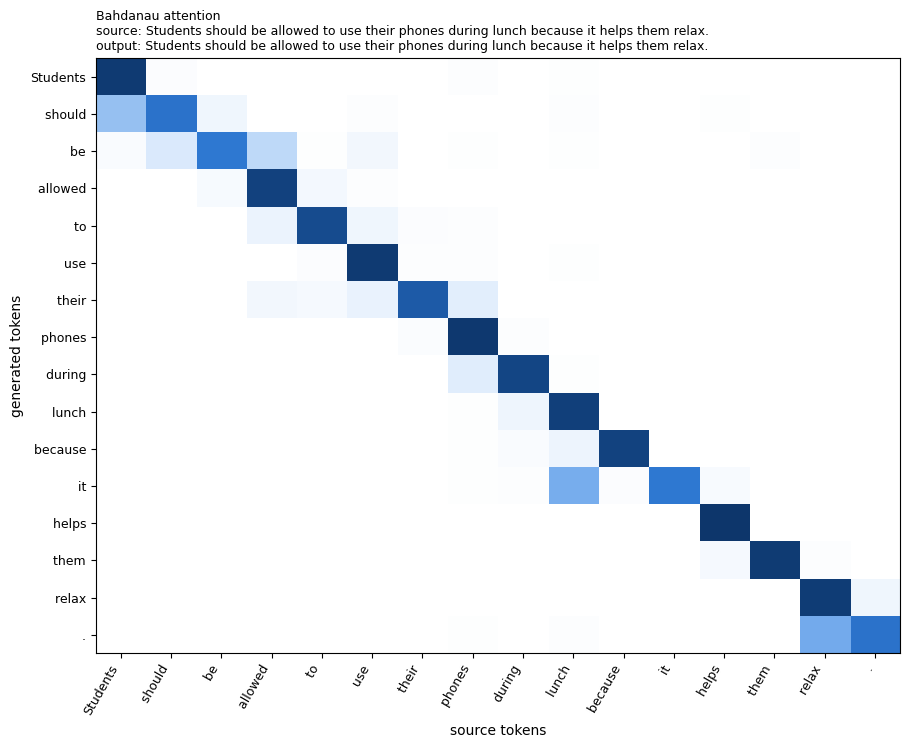

In [11]:
ex = "Students should be allowed to use their phones during lunch because it helps them relax."
src_ids = enc_ids(gpt_tok(ex)['input_ids'])
out_ids, attn = paraphrase_ids(model, [src_ids], return_attn=True)
out_ids = out_ids[0]
A = attn[0, :len(out_ids), :len(src_ids)].numpy()
src_toks = [gpt_tok.decode([ours_to_gpt2.get(i, 0)]) if i >= len(SPECIALS) else '<unk>' for i in src_ids]
out_toks = [gpt_tok.decode([ours_to_gpt2[i]]) for i in out_ids]
fig, ax = plt.subplots(figsize=(0.45 * len(src_toks) + 2, 0.38 * len(out_toks) + 1.5))
ax.imshow(A, cmap=BLUES, aspect='auto', vmin=0, vmax=A.max())
ax.set_xticks(range(len(src_toks)), src_toks, rotation=60, ha='right', fontsize=9)
ax.set_yticks(range(len(out_toks)), out_toks, fontsize=9)
ax.set_xlabel('source tokens'); ax.set_ylabel('generated tokens')
ax.set_title(f'Bahdanau attention\nsource: {ex}\noutput: {decode(out_ids)}', fontsize=9, loc='left')
fig.tight_layout()
fig.savefig('../images/12_attention.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 8 — A first look at essay sentences

The real targets are AI essay sentences, which differ from both training corpora (longer, argumentative, school register). A few sentences from on-topic `test` AI essays, greedy and sampled:

In [12]:
ai_test = load_splits('test').query('label == 1 and on_topic')
sents = [s for t in ai_test['text'].sample(4, random_state=SEED) for s in re.split(r'(?<=[.!?])\s+', t.strip())[1:3]]
for s, g, p in zip(sents, paraphrase(model, sents), paraphrase(model, sents, sample=True)):
    print(f"source : {s}\ngreedy : {g}\nsampled: {p}\n")

source : However, this approach can be limiting and can lead to missed opportunities.
greedy : However, this approach can be limiting and can lead to missed opportunities.
sampled: However, this approach can be found and can lead to other kinds.

source : One of the main reasons why people rely on others to make decisions for them is because they fear hurting someone's feelings.
greedy : One of the main reasons why people rely on others to make decisions for them is because they fear hurting someone's feelings.
sampled: One of the main reasons why people rely on others to make decisions for them, because they like hurting someone's feelings.

source : It's like, super important for kids to learn how to relax and focus, you know?
greedy : It's like, super important for kids to learn and focus, you know?
sampled: It's like, super important for kids to learn how to relax and focus, you know?

source : But, I'm not sure if it should be a part of the school day.
greedy : But, I'm not sure i

## Step 9 — Save

Weights and the vocabulary mapping go to the git-ignored `models/`, so `13_attack` and the demo can load the paraphraser without retraining.

In [13]:
torch.save(model.state_dict(), '../models/paraphraser_gru.pt')
with open('../models/paraphraser_vocab.json', 'w') as f:
    json.dump({'kept_gpt2_ids': kept, 'max_tok': MAX_TOK, 'emb': 256, 'hid': 256}, f)
pd.DataFrame(rows).set_index('decoder').round(2).to_csv('../results/12_paraphraser.csv')
print(f"saved: {os.path.getsize('../models/paraphraser_gru.pt') / 1e6:.0f} MB")

saved: 272 MB


## Key takeaways

- **The architecture works as designed.** 68M parameters (54M of them in the 41,915-way output layer), 4 epochs on 449k directed pairs, ~105 min on the RTX 3050; val loss 3.51 → 3.19, still falling slowly. The attention heatmap is a clean diagonal: the decoder has learned to *align* each output token with the matching source token, which is exactly what Bahdanau attention is for.
- **But it learned that copying is the safest paraphrase.** Greedy decoding returns the input unchanged 36% of the time (self-BLEU 68); sampling 20% (self-BLEU 51). **Neither beats the copy-the-input baseline on BLEU vs the reference** (33.3 and 26.9 vs 39.2). Many training pairs are near-copies (Simple-Wiki edits, Quora rewordings), and cross-entropy rewards reproducing the source when unsure.
- **When it does change text, the edits are small and often damage meaning:** "advantages and **advantages**", "a small **restaurantard**", "because they **like** hurting someone's feelings" (meaning reversed), "online courses → **offer** courses". It's a *light, noisy word editor*, not a paraphraser.
- **On essay sentences it's weaker still**: long argumentative sentences sit outside its training distribution (questions and encyclopedia sentences), so it either copies them or garbles them.
- **What this means for the attack (`13`):** this model can only test "small local edits". Any drop in detection has to be read alongside the meaning damage it causes, otherwise "fooling the detector" just means "breaking the essay". It isn't a realistic stand-in for a student running an essay through a modern paraphrasing tool.
- **Why it still matters for the viva:** it's the syllabus's seq2seq + attention unit, built and trained from scratch, with a measured, explained failure mode (copying), a standard failure of small seq2seq models trained on noisy paraphrase data.
